# Liquid Al: comparing candidate liquid Cp models

Demonstrates the six liquid-phase heat capacity models in [`liquid_models.py`](../../liquid_models.py)
against real liquid-Al Cp data (`CpCSV/Al_liq_cp.csv`), fit independently with weighted
least squares. Al melts at 933.47 K; the dataset covers 933-1300 K, i.e. purely the
liquid phase.

Models compared:
1. `DulongPetitLiquidE` -- classical high-T limit, Cp = 3R + aT
2. `KelleyLiquidE` -- Kelley (1960), Cp = a + bT + c/T^2
3. `SGTELiquidE` -- Dinsdale (1991) SGTE unary polynomial
4. `EinsteinLinearLiquidE` -- Einstein oscillator + linear/quadratic (mirrors solid `RWModelE`)
5. `EinsteinQuarticLiquidE` -- Einstein oscillator + T^4 (mirrors solid `CSModelE`, Chen & Sundman 2001)
6. `TwoStateLiquidE` -- Einstein baseline + phenomenological excess-Cp bump, standing in for the
   Agren (1979) / Bigdeli et al. (2016) two-state liquid model

See `liquid_models.py` for full references and the caveats on the two-state stand-in.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import json
import os

sys.path.insert(0, os.path.join('..', '..'))  # repo root, for liquid_models.py
from liquid_models import (
    LIQUID_MODEL_REGISTRY,
    LIQUID_MODEL_PARAMS,
    LIQUID_MODEL_INITIAL_GUESS,
    LIQUID_MODEL_PRIORS,
)

plt.rcParams.update({'font.size': 13})

## Load liquid Al Cp data

`CpCSV/Al_liq_cp.csv` has three columns: `Temperature (K)`, `Heat capacity at constant
pressure Cp (J/K/mol)`, and `Uncertainty` (1-sigma, J/K/mol). Rows 12-28 duplicate rows
29-44 in the source compilation; both copies are kept as-is.

In [2]:
element = 'Al'
csv_path = os.path.join('..', '..', 'CpCSV', f'{element}_liq_cp.csv')
df = pd.read_csv(csv_path)
df.columns = ['Temp', 'Cp', 'Uncertainty']
df = df.sort_values('Temp').reset_index(drop=True)

temp = df['Temp'].to_numpy()
cp = df['Cp'].to_numpy()
sigma = df['Uncertainty'].to_numpy()

print(f'{len(df)} liquid Cp data points, T = [{temp.min():.1f}, {temp.max():.1f}] K')
df.head()

43 liquid Cp data points, T = [933.2, 1300.0] K


,Temp,Cp,Uncertainty
0,933.250,29.9000,0.897000
1,939.044,31.4083,0.251266
2,950.000,29.9000,0.897000
3,950.000,29.9000,0.897000
4,951.512,31.3053,0.250442


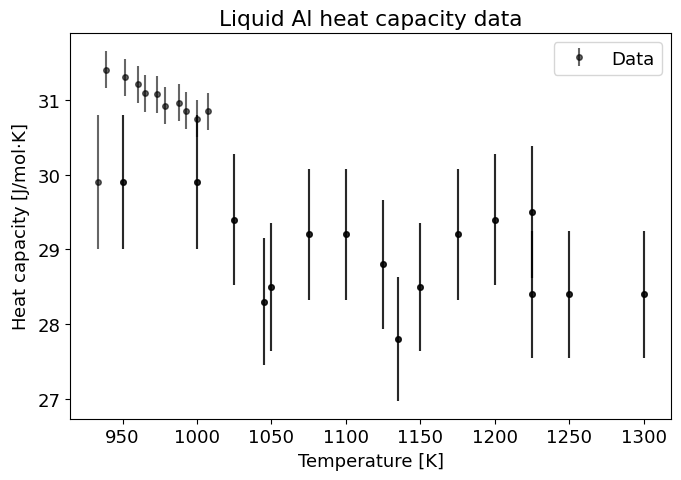

In [3]:
plt.figure(figsize=(7, 5))
plt.errorbar(temp, cp, yerr=sigma, fmt='o', color='k', ms=4, alpha=0.6, label='Data')
plt.xlabel('Temperature [K]')
plt.ylabel('Heat capacity [J/mol$\\cdot$K]')
plt.title(f'Liquid {element} heat capacity data')
plt.legend()
plt.tight_layout()
plt.savefig('Results/Al_liq_data.png', dpi=150)
plt.show()

## Fit each candidate model

Weighted nonlinear least squares (`scipy.optimize.curve_fit`, `sigma=Uncertainty`,
`absolute_sigma=True`) using the initial guesses from `liquid_models.LIQUID_MODEL_INITIAL_GUESS`,
bounded by the flat-prior ranges in `liquid_models.LIQUID_MODEL_PRIORS` so the fit can't drift
into unphysical territory (e.g. a negative Einstein temperature). Also computes AICc (corrected
Akaike Information Criterion) for model comparison, consistent with the convention used for the
solid models elsewhere in this repo.

In [4]:
def aicc(residuals, nparm, nobs):
    rss = np.sum(residuals ** 2)
    s2b = rss / nobs
    log_lik = -nobs / 2 * (np.log(2 * np.pi) - np.log(s2b)) - 1 / (2 * s2b) * rss
    aic = -2 * log_lik + 2 * (nparm + 1)
    k = nparm + 1
    if k >= nobs - 1:
        return np.inf
    return aic + (2 * k * (k + 1)) / (nobs - k - 1)


results = {}
fits = {}
for name, func in LIQUID_MODEL_REGISTRY.items():
    p0 = LIQUID_MODEL_INITIAL_GUESS[name]
    lo, hi = zip(*LIQUID_MODEL_PRIORS[name])
    try:
        popt, pcov = curve_fit(func, temp, cp, p0=p0, sigma=sigma, absolute_sigma=True,
                                bounds=(lo, hi), maxfev=20000)
    except RuntimeError as exc:
        print(f'{name}: fit failed ({exc})')
        continue
    resid = (func(temp, *popt) - cp)
    a = aicc(resid, len(popt), len(temp))
    results[name] = {'params': dict(zip(LIQUID_MODEL_PARAMS[name], popt)), 'AICc': a}
    fits[name] = popt
    print(f'{name:>22s}  AICc = {a:8.2f}   params = {np.round(popt, 6)}')

    DulongPetitLiquidE  AICc =    61.26   params = [0.005517]
         KelleyLiquidE  AICc =   142.16   params = [ 3.8191847e+01 -8.5390000e-03  1.0000000e+06]
           SGTELiquidE  AICc =   156.38   params = [ 1.00000000e+02 -1.04401000e-01 -4.81688552e+06  4.00000000e-05]
 EinsteinLinearLiquidE  AICc =    66.01   params = [0.172674 0.005517 0.      ]
EinsteinQuarticLiquidE  AICc =    66.02   params = [0.       0.005517 0.      ]
       TwoStateLiquidE  AICc =   107.14   params = [ 2.34444800e+00  5.92600000e-03 -4.99998948e+02  1.18550853e+03
  4.23091060e+01]


## Compare fits visually

All six fitted curves over the data, then individually for clarity.

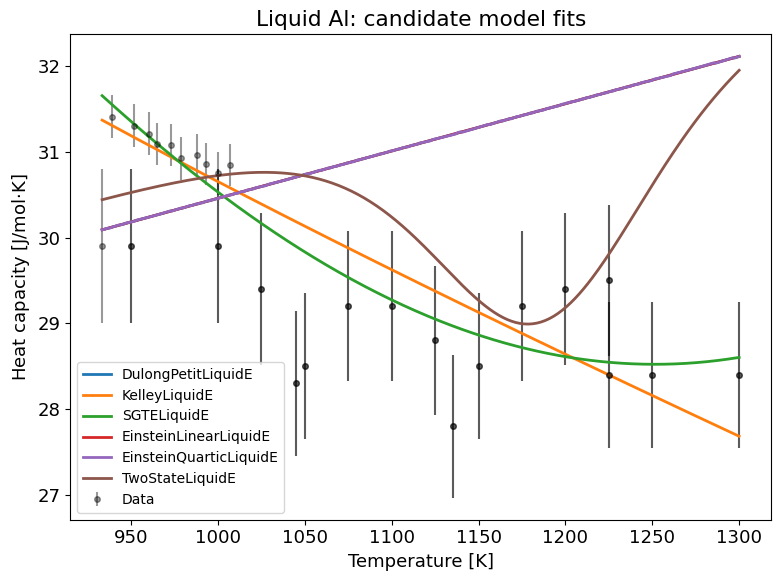

In [5]:
T_plot = np.linspace(temp.min(), temp.max(), 300)

plt.figure(figsize=(8, 6))
plt.errorbar(temp, cp, yerr=sigma, fmt='o', color='k', ms=4, alpha=0.4, label='Data')
for name, popt in fits.items():
    plt.plot(T_plot, LIQUID_MODEL_REGISTRY[name](T_plot, *popt), label=name, lw=2)
plt.xlabel('Temperature [K]')
plt.ylabel('Heat capacity [J/mol$\\cdot$K]')
plt.title(f'Liquid {element}: candidate model fits')
plt.legend(fontsize=10)
plt.tight_layout()
plt.savefig('Results/Al_liq_all_fits.png', dpi=150)
plt.show()

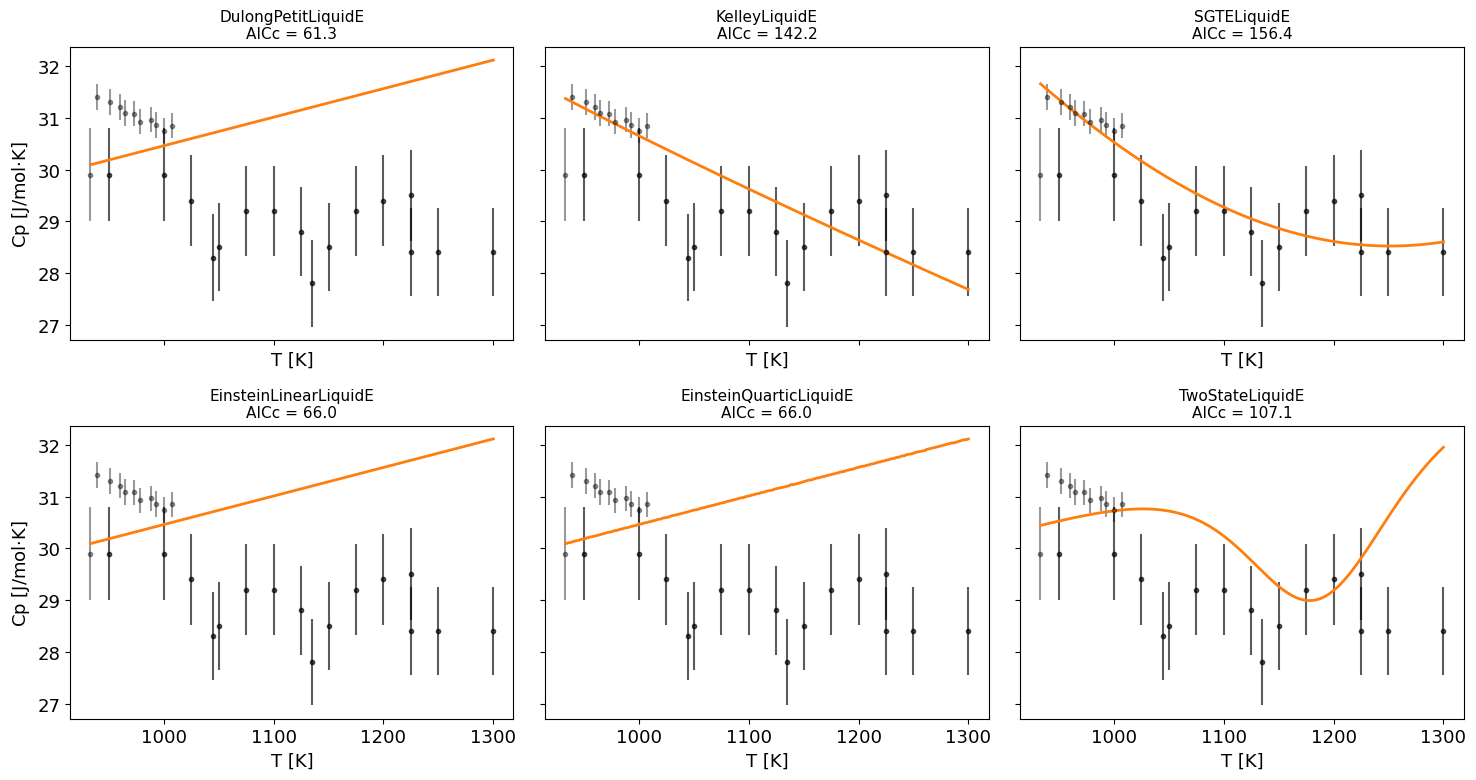

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
for ax, (name, popt) in zip(axes.flat, fits.items()):
    ax.errorbar(temp, cp, yerr=sigma, fmt='o', color='k', ms=3, alpha=0.4, label='Data')
    ax.plot(T_plot, LIQUID_MODEL_REGISTRY[name](T_plot, *popt), color='C1', lw=2, label='Fit')
    ax.set_title(f"{name}\nAICc = {results[name]['AICc']:.1f}", fontsize=11)
    ax.set_xlabel('T [K]')
axes[0, 0].set_ylabel('Cp [J/mol$\\cdot$K]')
axes[1, 0].set_ylabel('Cp [J/mol$\\cdot$K]')
plt.tight_layout()
plt.savefig('Results/Al_liq_fit_grid.png', dpi=150)
plt.show()

## Model ranking by AICc

Lower AICc indicates a better trade-off between fit quality and model complexity
(number of parameters) for this dataset.

In [7]:
ranking = pd.DataFrame(
    [(name, len(LIQUID_MODEL_PARAMS[name]), res['AICc']) for name, res in results.items()],
    columns=['model', 'n_params', 'AICc'],
).sort_values('AICc').reset_index(drop=True)
ranking

,model,n_params,AICc
0,DulongPetitLiquidE,1,61.256624
1,EinsteinLinearLiquidE,3,66.009254
2,EinsteinQuarticLiquidE,3,66.022509
3,TwoStateLiquidE,5,107.140489
4,KelleyLiquidE,3,142.158909
5,SGTELiquidE,4,156.384838


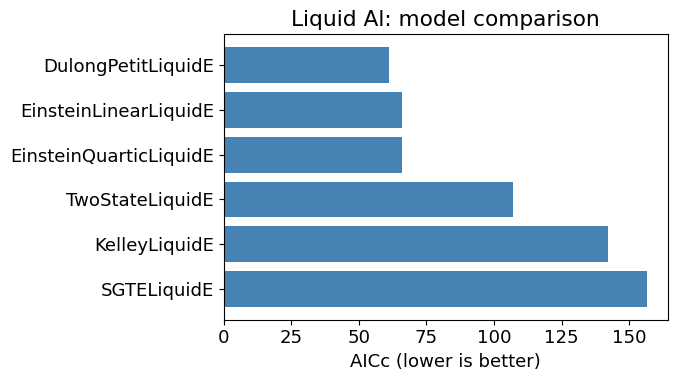

In [8]:
plt.figure(figsize=(7, 4))
plt.barh(ranking['model'], ranking['AICc'], color='steelblue')
plt.xlabel('AICc (lower is better)')
plt.title(f'Liquid {element}: model comparison')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('Results/Al_liq_aicc_ranking.png', dpi=150)
plt.show()

## Save fit results

Written in the same `{model: [params...], AICC_...: value}`-style convention used for
the solid-model outputs elsewhere in `41_Elements/FCC/Results/`.

In [9]:
output = {name: list(np.round(popt, 8)) for name, popt in fits.items()}
for name, res in results.items():
    output[f"AICC_{name}"] = res['AICc']

output_file = 'Results/Al_liq_output.json'
with open(output_file, 'w') as f:
    json.dump(output, f, indent=2, default=float)

print(f'Wrote {output_file}')

Wrote Results/Al_liq_output.json
